# Functions

## What are functions?

Functions are reusable blocks of code that perform a specific task. They help streamline your code by allowing you to avoid repetition, improve readability, and make maintenance easier.

The general syntax for defining a function is the following:

```python
def function_name(parameter_1, ..., parameter_n):
    """Docstring"""
    <body of the function>
    return value  # Depending on the function
```

In [22]:
# Example 1: one-line docstring, no parameters, no return value
def greet():
    """Print a greeting message."""
    print("Hello, welcome to the class!")

greet()

Hello, welcome to the class!


In [23]:
# Example 2: multi-line docstring, parameters, and return value
def calculate_area(radius):
    """
    Calculate the area of a circle given its radius.
    
    Args:
        radius (float): The radius of the circle.
        
    Returns:
        float: The area of the circle, calculated as π * radius^2.
    """
    area = 3.14159 * radius ** 2
    return area

# Using our function
for radius in [1, 2, 3, 4, 5]:
    area = calculate_area(radius)
    print(f"The area of a circle with radius {radius} is {area:.2f}")

The area of a circle with radius 1 is 3.14
The area of a circle with radius 2 is 12.57
The area of a circle with radius 3 is 28.27
The area of a circle with radius 4 is 50.27
The area of a circle with radius 5 is 78.54


In [24]:
help(calculate_area)

Help on function calculate_area in module __main__:

calculate_area(radius)
    Calculate the area of a circle given its radius.
    
    Args:
        radius (float): The radius of the circle.
    
    Returns:
        float: The area of the circle, calculated as π * radius^2.



## Adding checks with `assert`

Sometimes we want a function to stop and give a helpful message when it gets an input that doesn't make sense. We can do this with an `assert` statement, like we did to check our data:

```python
assert <condition that should be True>, "Message explaining what went wrong"
```

Let's update `calculate_area` so it gives an error when the radius is negative:

In [25]:
def calculate_area(radius):
    """
    Calculate the area of a circle given its radius.
    
    Args:
        radius (float): The radius of the circle.
        
    Returns:
        float: The area of the circle, calculated as π * radius^2.
    """
    # Check that radius is not negative
    assert radius >= 0, f"radius must be non-negative, got {radius}"

    area = 3.14159 * radius ** 2
    return area

# Check if the assertion works
calculate_area(-2)

AssertionError: radius must be non-negative, got -2

In production code, input checks like this one are usually written with `raise` instead of `assert`, but `assert` works well at this stage. You can learn more about `raise` [here](https://realpython.com/python-raise-exception/). The core idea is that you can build in checks to test the inputs and outputs of your functions.

## Global variables

A **global variable** is a variable defined outside of any function, for example directly in a notebook cell. Functions can use global variables even if we don't pass them as parameters. Let's see why this can be a problem:

In [26]:
threshold = 30   # °C

def is_hot(temp):
    """Check if a temperature is above the threshold."""
    return temp > threshold

print(is_hot(32))   # True

# Later in the notebook, for another analysis...
threshold = 50

print(is_hot(32))   # False: same input, different answer!

True
False


`is_hot` uses the global variable `threshold`, so its result changed even though we passed the same temperature. We can fix this by making `threshold` a parameter:

In [18]:
def is_hot(temp, threshold):
    """Check if a temperature is above a threshold."""
    return temp > threshold

print(is_hot(32, 30))   # True
print(is_hot(32, 50))   # False

True
False


Now the result depends only on what we pass to the function. 

**The best practice is for every variable used inside a function to be either a parameter or defined inside the function.**

We'll come back to this when we write our own functions.

## Data loading and preparation

We'll practice creating functions using the same datasets from the previous lesson.

In [27]:
import os
import pandas as pd

import geopandas as gpd
import matplotlib.pyplot as plt

# Display all columns when looking at dataframes
pd.set_option("display.max.columns", None)

# --------------------------------------------------
# Import power plants data
URL = 'https://raw.githubusercontent.com/carmengg/eds-220-book/refs/heads/main/data/power_plants_epsg4269.csv'
power_plants = pd.read_csv(URL)

# Import states data
fp = os.path.join('..', 'data','tl_2026_us_state','tl_2026_us_state.shp')
states = gpd.read_file(fp)
states.columns = states.columns.str.lower()

# --------------------------------------------------
# Create geometry column for power plants
points = gpd.points_from_xy(power_plants.longitude,
                            power_plants.latitude)

# Convert power plants DataFrame to GeoDataFrame
power_plants = gpd.GeoDataFrame(power_plants,      # Data
                                geometry=points,   # Specify geometry column
                                crs='EPSG:4269'    # Specify CRS
                                )


## Previous work: CA top power plant sources map

Last lesson we solved the following exercise using a `for` loop with `zip` to create subplots of the top 3 most frequent power plant sources in California.

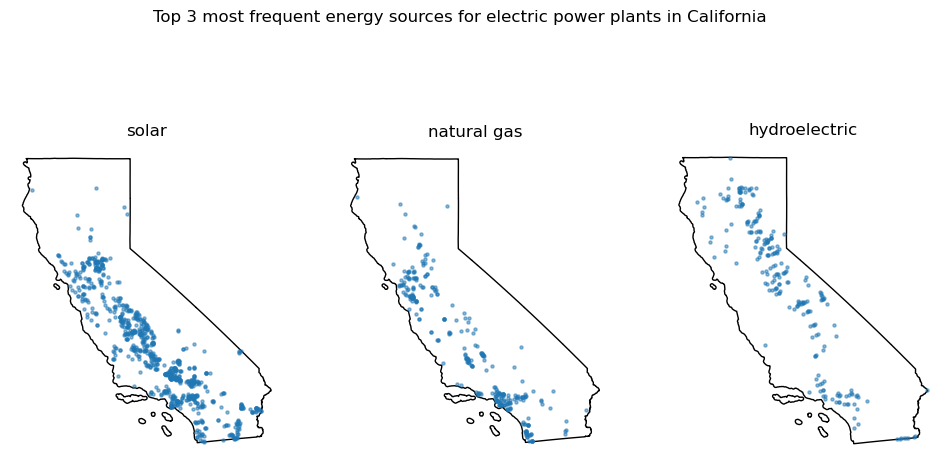

In [ ]:
# --- Find top sources by number of plants

ca_power_plants = power_plants[power_plants['state']=='California']
ca_top_sources = (ca_power_plants['primsource']
                            .value_counts()
                            .index[:3]
                            .tolist()
                            )
# --- Plot

# Select CA state boundary
ca_boundary = states[states['name'] == 'California']

# Create subplots for each top source in a single figure
fig, ax = plt.subplots(figsize=(12,6), nrows=1, ncols=3)
for axis, source in zip(ax, ca_top_sources):   # Iterate over subplots and energy sources

    axis.set_title(source)
    axis.axis('off')

    ca_boundary.plot(ax=axis,
                     color='none')
    
    # Subset power plants by source and plot
    source_subset = ca_power_plants[ca_power_plants['primsource'] == source]
    source_subset.plot(ax=axis,
                    markersize=5,
                    alpha=0.5)

fig.suptitle(f"Top 3 most frequent energy sources for electric power plants in California")    
plt.show()

## Steps to create a function

Our previous code "hard-codes" California, so it only works for that state.

Let's make a function that finds the top 3 power sources for any state! My general advice to break down this problem is:

- Step 1: solve the problem for a concrete example
- Step 2: identify which parts of the code need to be generalized and update them
- Step 3: wrap the code inside a function
- Step 4: turn global variables inside the function into parameters
- Step 5: add a docstring and tests as needed


### Step 1: solve the problem for a concrete example

My recommendation is to first write code that solves the problem just for a specific example (e.g., California). Don't even think about the function yet. 

In our case we need to:

1. Subset power plants for the given state
    
2. Count how many times each power source appears in that subset
    
3. Sort counts and select the top 3; this should be a list

You can do this part mentally, but it can be useful to actually write down what steps you need to take.

Let's implement steps 1-3.

In [30]:
state = 'California'

state_power_plants = power_plants[power_plants['state']=='California']
state_top_sources = (state_power_plants['primsource']
                            .value_counts()
                            .index[:3]
                            .tolist()
                            )
state_top_sources

['solar', 'natural gas', 'hydroelectric']

Great, now that we have code that works for a specific example, let's turn it into a function!

### Step 2: identify what parts of the code need to be generalized

In our case, we need to have the function work for any state, not just California. So we need to generalize the state name to be its own variable. We do this by replacing 'California' with a variable called `state` and re-run things to make sure it still works.

In [ ]:
state = 'California'

state_power_plants = power_plants[power_plants['state']=='California']
state_top_sources = (state_power_plants['primsource']
                            .value_counts()
                            .index[:3]
                            .tolist()
                            )
state_top_sources

### Step 3: wrap the code inside a function
Now we can wrap the code into a function. The variable becomes a parameter for the function.

Make sure everything is properly indented.

In [43]:
def top_3_sources(state):
    state_power_plants = power_plants[power_plants['state'] == state]
    state_top_sources = (state_power_plants['primsource']
                            .value_counts()
                            .index[:3]
                            .tolist()
                            )
    return state_top_sources

In [44]:
top_3_sources('California')

['solar', 'natural gas', 'hydroelectric']

In [46]:
for state in ['New Jersey', 'New York', 'Pennsylvania']:
    print(f"{state}: {top_3_sources(state)}")

New Jersey: ['solar', 'natural gas', 'biomass']
New York: ['solar', 'hydroelectric', 'natural gas']
Pennsylvania: ['natural gas', 'solar', 'petroleum']


### Step 4: turn global variables used inside the function into parameters

Here we ask: is every variable used inside a function to be either a parameter or defined inside the function?

The only variable used in the function that is not defined in the function's body or passed as a parameter is `power_plants`. 

We turn it into a parameter called `plants`:

In [47]:
def top_3_sources(state, plants):
    state_power_plants = plants[plants['state'] == state]
    state_top_sources = (state_power_plants['primsource']
                            .value_counts()
                            .index[:3]
                            .tolist()
                            )
    return state_top_sources

In [52]:
for state in ['New Jersey', 'New York', 'Pennsylvania']:
    print(f"{state}: {top_3_sources(state, power_plants)}")

New Jersey: ['solar', 'natural gas', 'biomass']
New York: ['solar', 'hydroelectric', 'natural gas']
Pennsylvania: ['natural gas', 'solar', 'petroleum']


### Step 5: add a docstring and tests as needed
Finally, we can add a docstring to explain what the function does, its parameters, and its return values. We also use `assert` to check that the state is in the data.

In [ ]:
def top_3_sources(state, plants):
    '''Find the top 3 electric primary sources with the most plants for a given state.'''

    # Check that state is in the plants data
    assert state in plants['state'].values
    
    state_power_plants = plants[plants['state'] == state]
    state_top_sources = (state_power_plants['primsource']
                            .value_counts()
                            .index[:3]
                            .tolist()
                            )
    return state_top_sources

Let's check that our error works with a misspelled state name:

In [ ]:
help

## Exercise 1

Create a function called `power_source_counts` that, given a power source, returns a Series with the counts of power plants by state that use that source.

Follow the steps:

- Step 1: solve the problem for a concrete example
- Step 2: identify which parts of the code need to be generalized and update them
- Step 3: wrap the code inside a function
- Step 4: turn global variables inside the function into parameters
- Step 5: add a docstring and tests as needed

In [62]:
def power_source_counts(source, plants):
    '''Find the power source for any given state.'''

    # Check that power source is in the power plants data
    assert source in power_plants['primsource'].values
    
    state_power_source = plants[plants['primsource'] == source]
    state_power_source['primsource'].value_counts()
    return state_power_source

In [63]:
power_source_counts('wind').head()

TypeError: power_source_counts() missing 1 required positional argument: 'plants'

## Example: plot the top 3 sources for any state

Create a function that will produce a plot given a list of primary sources and a state name.

We can start with the code we had for California. 

In [ ]:
def plot_top3_power_sources(state, plants, boundaries): 
    '''
    Plot the power plants of a given state for its top 3 primary energy sources by number of plants. 
    Args: 
        state (str): the state we want to plot
        plants (gpd.GeoDataFrame): contains the power plants data (points)
        boundaries (gpd.GeoDataFrame): US states boundaries (polygons)
    '''

    # --- Find top sources by number of plants
    state_top_sources = top_3_sources(state, plants)
    # --- Plot

    # Select CA state boundary
    state_boundary = boundaries[boundaries['name'] == state]
    state_power_plants = plants[plants['state'] == state]

    # Create subplots for each top source in a single figure
    fig, ax = plt.subplots(figsize=(12,6), nrows=1, ncols=3)
    for axis, source in zip(ax, state_top_sources):   # Iterate over subplots and energy sources

        axis.set_title(source)
        axis.axis('off')

        state_boundary.plot(ax=axis,
                        color='none')
        
        # Subset power plants by source and plot
        source_subset = state_power_plants[state_power_plants['primsource'] == source]
        source_subset.plot(ax=axis,
                        markersize=5,
                        alpha=0.5)

    fig.suptitle(f"Top 3 most frequent energy sources for electric power plants in {state}")    
    plt.show()

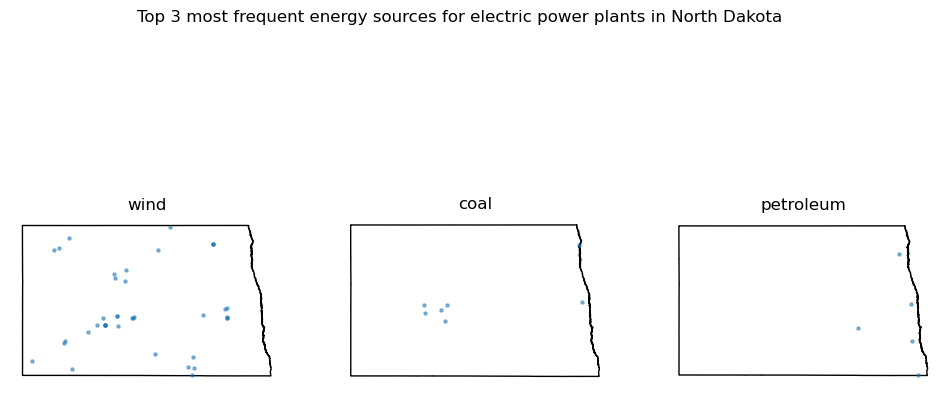

In [77]:
plot_top3_power_sources('North Dakota', power_plants, states)

Writing functions can feel challenging at first, but with practice, they'll start to come naturally whenever you find yourself reusing blocks of code. Keep experimenting and practicing—it gets easier with each function you write!

## Exercise 2

1. Recreate the following plot.
2. Make a function that produces this plot for any power source.
3. Brainstorm ways in which your function might break or not produce the desired output.

![](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/images/week6-exercise1.png){width=50%}

## Bonus

Create a function that, for a given power source, produces a plot like this one. Many ways of doing it, a hint could be to zip three things together: the axes, the top 3 states, and the counts of power plants in those states.

```python
# Example of more than two zipped items

for a, b, c in zip([1,2,3], ['x','y','z'], [10,20,30]):
    print(a, b, c)
```

![](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/images/week6-exercise2.png){width=50%}

In [ ]:
# Example of more than two zipped items

for a, b, c in zip([1,2,3], ['x','y','z'], [10,20,30]):
    print(a, b, c)